# Basic Exploratory Data Analysis: Crop Yield


In [1]:
import pandas as pd
import matplotlib.pyplot as plt


# Part 1: Data Loading & Basic Exploration

### 1. Load `crop_yield.csv` into a DataFrame named `crop_df`


In [3]:
crop_df = pd.read_csv("crop_yield.csv")

In [4]:
crop_df.shape

(3000, 9)

`shape` gives (rows, columns): the file has **3,000 rows and 9 columns**.

### 2. Display the first 10 rows
`head(10)` shows the first 10 rows (plain `head()` shows 5).

In [5]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


### 3. Check missing values in each column
`isnull()` marks every empty cell as True and `sum()` adds them up per column.

Missing values found: `YIELD_KG` **330**, `AREA_ACRES` **144**, `DISTRICT` **126**, `FERTILIZER_USED` **318**. All other columns are complete.

In [6]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

### 4. View the data types of all columns


In [7]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

Note that `HARVEST_DATE` is stored as `str` (text), not as a date. We fix that in step 12.

### 5. Statistical summary of all numeric columns
`describe()` gives count, mean, std, min, quartiles and max for the number columns. `count` is lower than the row count where values are missing.

In [8]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


### 6. Statistical summary of all object (text) columns
`describe(exclude="number")` summarises every column that is not a number, which means all the text columns. For each it shows `count` (non-empty values), `unique` (how many different values), `top` (most frequent value) and `freq` (how often the top value appears).

In [9]:
crop_df.describe(exclude="number")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


---
# Part 2: Data Cleaning

### 7. Remove all rows where `YIELD_KG` is missing
`dropna(subset=["YIELD_KG"])` drops only the rows where that one column is empty (plain `dropna()` would drop rows with a missing value in *any* column). We save the result back into `crop_df`.

**330 rows were removed, leaving 2,670.**

In [10]:
crop_df = crop_df.dropna(subset=["YIELD_KG"])
crop_df.shape

(2670, 9)

### 8. Fill missing `AREA_ACRES` with the mean of that column
`fillna(value)` replaces empty cells with `value`. Here the value is the column average (**about 4.41 acres**, calculated after step 7).

In [11]:
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(crop_df["AREA_ACRES"].mean())

### 9. Replace missing `DISTRICT` with the string 'Unknown'
The district is text, so we cannot use an average. We fill with a label instead.

In [12]:
crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")

### 10. Replace missing `FERTILIZER_USED` with the string 'No'
We assume that if fertilizer use was not recorded, none was used.

In [13]:
crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

### 11. Replace missing `YIELD_VALUE` with the mean of the column
Same pattern as step 8. In this file `YIELD_VALUE` has no missing values (see step 3), so this line changes nothing, but it is still the correct step.

In [14]:
crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(crop_df["YIELD_VALUE"].mean())

### 12. Convert `HARVEST_DATE` to datetime
`pd.to_datetime()` turns text into real dates.
- `format="%d/%m/%Y"` tells pandas the text is day/month/year (e.g. 01/01/2023). `%d` = day, `%m` = month, `%Y` = 4-digit year.
- `errors="coerce"` turns any invalid date into `NaT` (the date version of NaN) instead of crashing.

In [15]:
crop_df["HARVEST_DATE"] = pd.to_datetime(crop_df["HARVEST_DATE"], errors="coerce", format="%d/%m/%Y")

### 13. Remove the letter 'F' from `FARM_ID` and convert it to integer
- `.str.replace("F", "")` removes the letter from every text value, so `F001` becomes `001`.
- `.astype(int)` converts the text to a whole number, so `001` becomes `1`.

In [16]:
crop_df["FARM_ID"] = crop_df["FARM_ID"].str.replace("F", "").astype(int)

In [17]:
crop_df.head()

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,1,Wheat,1500.0,4.000000,2023-01-01,Sialkot,Rabi,Yes,30000
1,2,Wheat,1500.0,5.000000,2023-01-02,Multan,Rabi,No,30000
2,3,Wheat,2500.0,5.000000,2023-01-03,Faisalabad,Rabi,Yes,50000
3,4,Wheat,1500.0,4.412667,2023-01-04,Multan,Rabi,Yes,30000
4,5,Rice,1500.0,4.000000,2023-01-05,Faisalabad,Rabi,No,30000


### 14. Re-check missing values after cleaning
Every column should now show 0.

In [18]:
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

### 15. Re-check data types after cleaning
`FARM_ID` is now `int64` and `HARVEST_DATE` is now `datetime64`.

In [19]:
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

---
# Part 3: Data Analysis and Visualization

### 16. Total yield of each crop type
`groupby("CROP_TYPE")` puts the rows into one group per crop, and `agg({"YIELD_KG": "sum"})` adds up `YIELD_KG` inside each group.

**Wheat** has the highest total yield (2,035,500 kg) and **Sugarcane** the lowest (592,000 kg). Keep in mind that totals depend partly on how many farms grow each crop.

In [20]:
crop_total = crop_df.groupby("CROP_TYPE").agg({"YIELD_KG": "sum"})
crop_total

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


### 17. Bar chart of Total Yield by Crop Type (KG)
`plt.bar(x, y)` draws one bar per crop: `crop_total.index` holds the crop names and `crop_total["YIELD_KG"]` the totals. Then we add the axis labels and title, and `plt.show()` displays the chart. The `1e6` at the top of the y-axis means the values are in millions (2.00 = 2,000,000 kg).

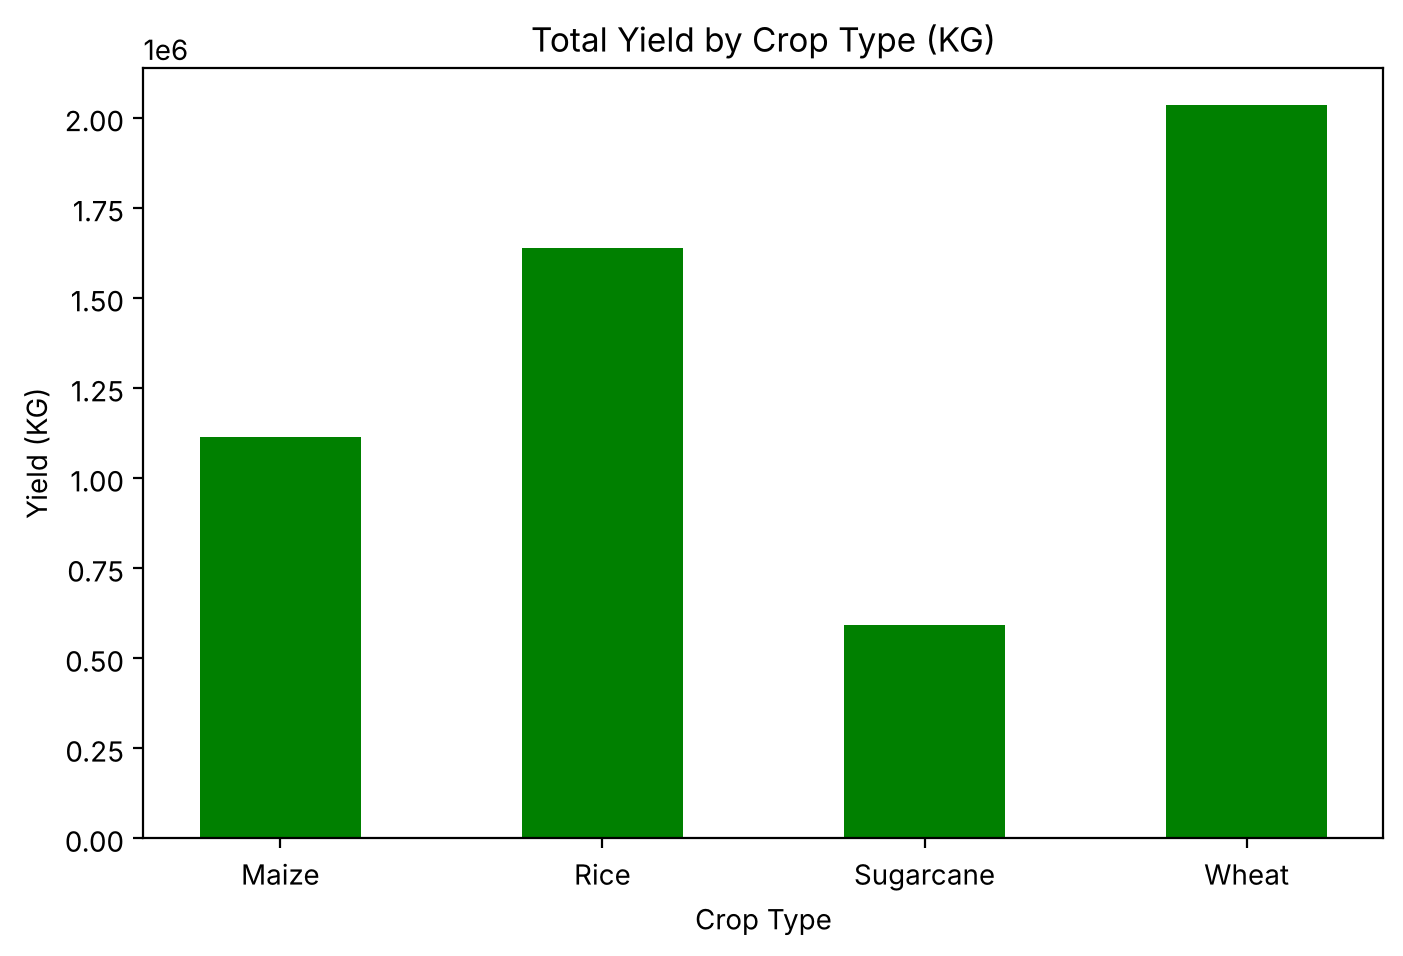

In [21]:
plt.figure(figsize=(8, 5))
plt.bar(crop_total.index, crop_total["YIELD_KG"], color="green", width=0.5)
plt.xlabel("Crop Type")
plt.ylabel("Yield (KG)")
plt.title("Total Yield by Crop Type (KG)")
plt.show()

### 18. Pivot table of total yield by harvest date

In [22]:
yield_pivot = crop_df.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
yield_pivot.head(10)

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
2023-01-06,2000.0
2023-01-07,1500.0
2023-01-08,1500.0
2023-01-09,2000.0


In [23]:
yield_pivot.shape

(2670, 1)

### 19. (From the hints) Line chart of the yield trend over time, saved as `crop_yield_trend.png`


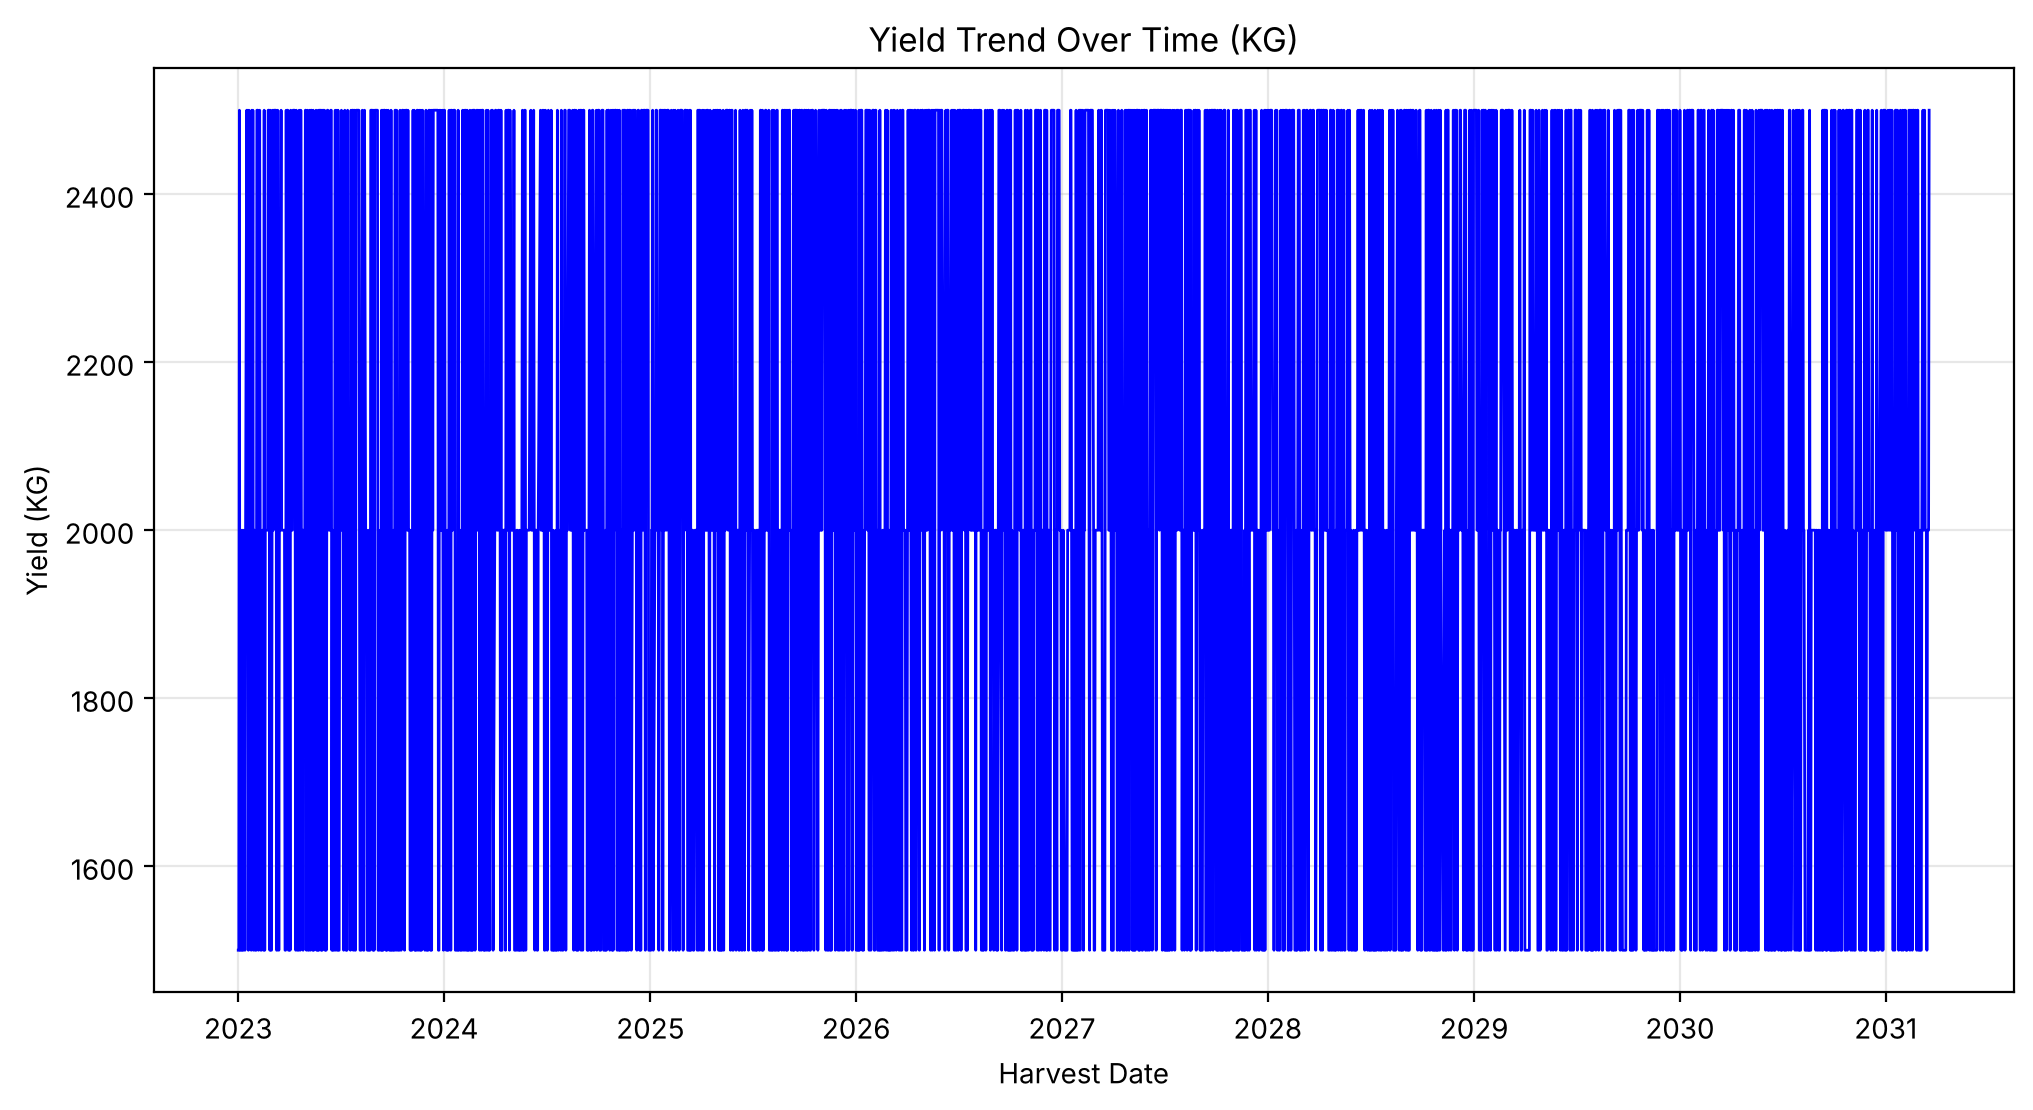

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(yield_pivot.index, yield_pivot["YIELD_KG"], color="blue", linewidth=1)
plt.xlabel("Harvest Date")
plt.ylabel("Yield (KG)")
plt.title("Yield Trend Over Time (KG)")
plt.grid(True, alpha=0.3)
plt.savefig("crop_yield_trend.png", dpi=300, bbox_inches="tight")
plt.show()